# 🧠 Reg_Aymen — 3D NIfTI Edition

> **Direct adaptation of your 2D pipeline → 3D volumetric registration**  
> Same architecture: HomographyNet + MINE, multi-resolution, GPU-accelerated  
> Images: `.nii` / `.nii.gz` volumetric medical images

---
### What changed vs the 2D version
| Component | 2D (original) | 3D (this notebook) |
|-----------|--------------|--------------------|
| Image loading | `cv2.imread` (PNG/JPG) | `nibabel.load` (NIfTI) |
| Data shape | `[H, W]` or `[H, W, C]` | `[X, Y, Z]` |
| Pyramid | `skimage.pyramid_gaussian` 2D | 3D Gaussian pyramid (scipy) |
| Edge sampling | `cv2.Canny` 2D | 3D Sobel gradient magnitude |
| Affine warp | `F.grid_sample` 2D `[1,C,H,W]` | `F.grid_sample` 3D `[1,1,D,H,W]` |
| HomographyNet | 3×3 homography matrix | **4×4 affine matrix** (3D rigid+affine) |
| Grid | `[H,W,2]` xy | `[D,H,W,3]` xyz |
| Visualization | `plt.imshow` | Axial / Coronal / Sagittal slicers |
| Save | `cv2.imwrite` PNG | `nibabel.save` NIfTI |

---
### Install
```bash
pip install nibabel torch torchvision scipy scikit-image matplotlib numpy ipywidgets
```

---
## Cell 1 — Imports & GPU Setup

In [14]:
# ============================================================
# CELL 1 — Imports & GPU setup
# ============================================================
import os
import math
import time
import random
import numpy as np
import nibabel as nib                       # ← NEW: replaces cv2 for loading
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from scipy.ndimage import gaussian_filter   # ← NEW: 3D Gaussian smoothing
from scipy.ndimage import zoom as scipy_zoom

# Reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Speed options
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

Device: cuda
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


---
## Cell 2 — Load NIfTI Images (Fixed & Moving)

I (fixed)  shape: (193, 229, 193)   spacing: (1.0, 1.0, 1.0) mm
J (moving) shape: (400, 400, 110)   spacing: (1.018, 1.018, 1.5) mm
⚠️  Shape mismatch → resampling J to I grid with scipy.ndimage.zoom
   J resampled to: (193, 229, 193)


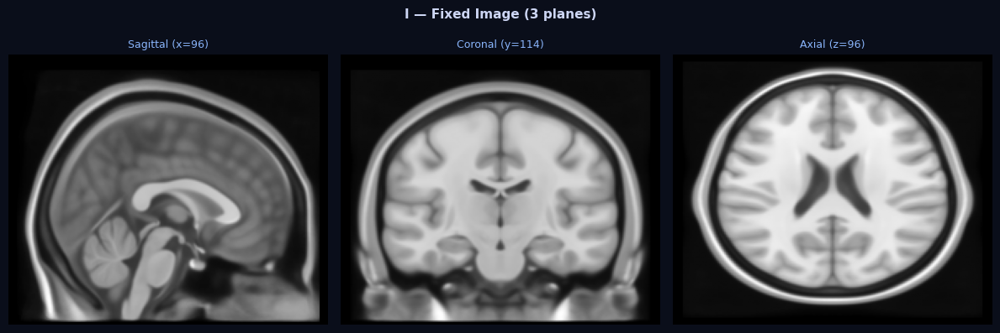

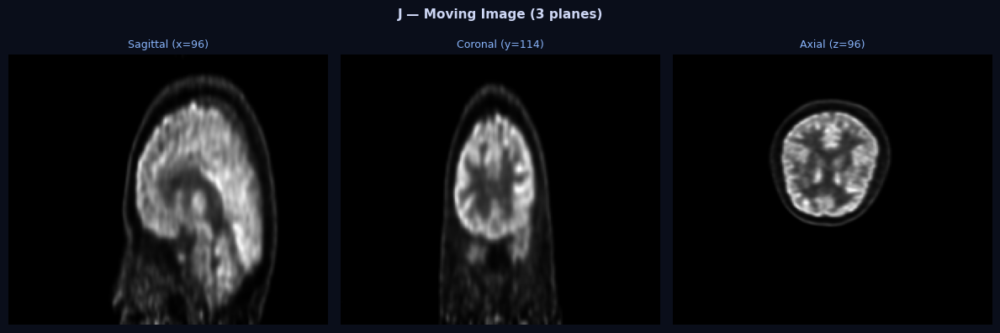

In [36]:
# ============================================================
# CELL 2 — Load images  (I: fixed, J: moving)
# ============================================================
# >>> Replace with your paths
# I_path = "D:/registration 3d/IRM_J_warped.nii.gz"    # fixed image  (reference)
# J_path = "D:/registration 3d/IRM_PET_J_warped.nii.gz.nii"   # moving image (to warp)
# OUT_DIR = "D:/registration 3d/IRM_PET_warped.nii"

# I_path = "D:/registration 3d/cT_IRM.nii/J_moving_norm.nii.gz"    # fixed image  (reference)
# J_path = "D:/registration 3d/cT_IRM.nii/IRM_J_warped.nii.gz"   # moving image (to warp)
# OUT_DIR = "D:/registration 3d/test 10 10 2026"
I_path  = "D:/registration 3d/MNI152.nii"   # fixe
J_path  = "D:/registration 3d/971882.nii"    # mobile
OUT_DIR = "D:/registration 3d/test_v2_12_10_rania2"
os.makedirs(OUT_DIR, exist_ok=True)

# ── Load with nibabel ─────────────────────────────────────────────────────────
I_nib = nib.load(I_path)
J_nib = nib.load(J_path)
I_nib = nib.as_closest_canonical(I_nib)
J_nib = nib.as_closest_canonical(J_nib)
I_raw = I_nib.get_fdata(dtype=np.float32)   # shape [X, Y, Z]  (or [X,Y,Z,T])
J_raw = J_nib.get_fdata(dtype=np.float32)

# Take only first volume if 4D (e.g. fMRI)
if I_raw.ndim == 4: I_raw = I_raw[..., 0]
if J_raw.ndim == 4: J_raw = J_raw[..., 0]

print("I (fixed)  shape:", I_raw.shape, "  spacing:",
      tuple(round(float(v),3) for v in I_nib.header.get_zooms()[:3]), "mm")
print("J (moving) shape:", J_raw.shape, "  spacing:",
      tuple(round(float(v),3) for v in J_nib.header.get_zooms()[:3]), "mm")

# ── Resample J to I grid if shapes differ ────────────────────────────────────
if I_raw.shape != J_raw.shape:
    print("⚠️  Shape mismatch → resampling J to I grid with scipy.ndimage.zoom")
    factors = tuple(s_i / s_j for s_i, s_j in zip(I_raw.shape, J_raw.shape))
    J_raw = scipy_zoom(J_raw, factors, order=3)   # B-spline order 3
    print("   J resampled to:", J_raw.shape)

# ── Quick 3-plane preview ─────────────────────────────────────────────────────
def quick_preview(vol, title, cmap='gray'):
    x, y, z = vol.shape[0]//2, vol.shape[1]//2, vol.shape[2]//2
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    fig.patch.set_facecolor('#0a0e1a')
    planes = [vol[x,:,:], vol[:,y,:], vol[:,:,z]]
    labels = [f'Sagittal (x={x})', f'Coronal (y={y})', f'Axial (z={z})']
    for ax, pl, lbl in zip(axes, planes, labels):
        ax.imshow(pl.T, cmap=cmap, origin='lower', aspect='auto')
        ax.set_title(lbl, color='#89b4fa', fontsize=9)
        ax.axis('off')
        ax.set_facecolor('#0a0e1a')
    fig.suptitle(title, color='#cdd6f4', fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.show()

quick_preview(I_raw, "I — Fixed Image (3 planes)")
quick_preview(J_raw, "J — Moving Image (3 planes)")

---
## Cell 3 — Utils (3D adapted)

In [37]:
# ============================================================
# CELL 3 — Utils  (all 3D)
# ============================================================

def robust_norm01(x: np.ndarray, p_low=1, p_high=99) -> np.ndarray:
    """Percentile normalisation → [0, 1].  Works for any dimensionality."""
    x = x.astype(np.float32)
    lo, hi = np.percentile(x, p_low), np.percentile(x, p_high)
    if hi <= lo:
        return np.zeros_like(x, dtype=np.float32)
    return np.clip((x - lo) / (hi - lo), 0.0, 1.0).astype(np.float32)


def gradient_magnitude_3d(vol: np.ndarray) -> np.ndarray:
    """
    3D equivalent of Canny edges: Sobel gradient magnitude.
    Replaces cv2.Canny which only works on 2D.
    vol: float [0,1] shape [X,Y,Z]
    returns: float [0,1] gradient magnitude
    """
    from scipy.ndimage import sobel
    gx = sobel(vol, axis=0)
    gy = sobel(vol, axis=1)
    gz = sobel(vol, axis=2)
    mag = np.sqrt(gx**2 + gy**2 + gz**2)
    # threshold at 50th percentile to get informative voxels
    thr = np.percentile(mag, 50)
    return (mag > thr).astype(np.float32)


def pyramid_gaussian_3d(vol: np.ndarray, downscale: float, max_levels: int):
    """
    3D Gaussian pyramid.
    Replaces skimage.transform.pyramid_gaussian which is 2D.
    Returns list: [level_0_full_res, level_1, ..., level_max_levels]
    """
    levels = [vol.astype(np.float32)]
    current = vol.astype(np.float32)
    for _ in range(max_levels):
        sigma = downscale / 2.0
        blurred = gaussian_filter(current, sigma=sigma)
        factor  = 1.0 / downscale
        downsampled = scipy_zoom(blurred, factor, order=1)
        levels.append(downsampled.astype(np.float32))
        current = downsampled
        if min(current.shape) < 4:
            break
    return levels


def make_grid_3d(D, H, W, device):
    """
    Build a normalised grid [-1,1] in 3D.
    Returns: [D, H, W, 3]  (x=W-axis, y=H-axis, z=D-axis)
    Replaces the 2D [H,W,2] grid.
    """
    z_ = torch.linspace(-1, 1, D, device=device, dtype=torch.float32)
    y_ = torch.linspace(-1, 1, H, device=device, dtype=torch.float32)
    x_ = torch.linspace(-1, 1, W, device=device, dtype=torch.float32)
    gz, gy, gx = torch.meshgrid(z_, y_, x_, indexing='ij')  # each [D,H,W]
    return torch.stack([gx, gy, gz], dim=-1)                 # [D,H,W,3]


print("✅ 3D utils ready")

✅ 3D utils ready


---
## Cell 4 — Build 3D Pyramids

Available pyramid levels: 5   Used: L=5
  Level 0: I=(193, 229, 193)  J=(193, 229, 193)
  Level 1: I=(96, 114, 96)  J=(96, 114, 96)
  Level 2: I=(48, 57, 48)  J=(48, 57, 48)
  Level 3: I=(24, 28, 24)  J=(24, 28, 24)
  Level 4: I=(12, 14, 12)  J=(12, 14, 12)


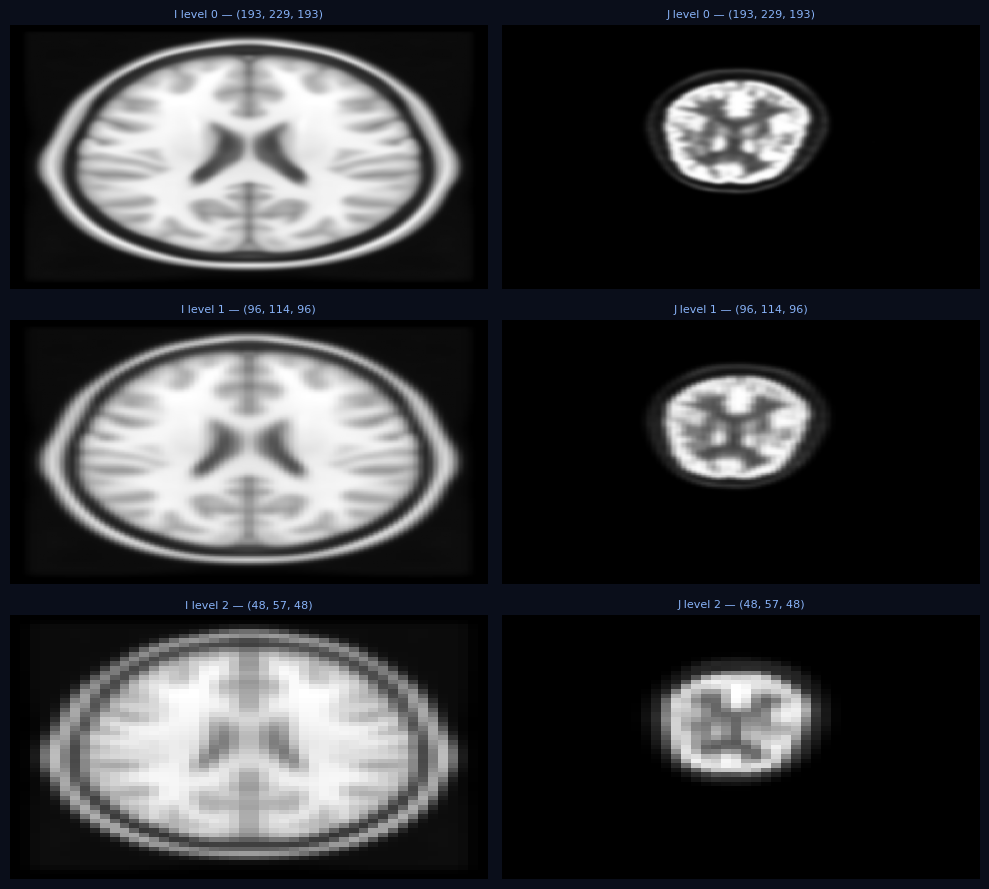

In [38]:
# ============================================================
# CELL 4 — Build 3D Pyramids
# ============================================================
# ── Tuning ───────────────────────────────────────────────────
downscale  = 2.0
max_levels = 4    # total levels generated
L          = 5    # levels actually used for registration (coarse → fine)
# ─────────────────────────────────────────────────────────────

I0 = robust_norm01(I_raw)
J0 = robust_norm01(J_raw)

# Smooth before downsampling (anti-aliasing)
I0_smooth = gaussian_filter(I0, sigma=1.0)
J0_smooth = gaussian_filter(J0, sigma=1.0)

pyramid_I = pyramid_gaussian_3d(I0_smooth, downscale, max_levels)
pyramid_J = pyramid_gaussian_3d(J0_smooth, downscale, max_levels)

L = min(L, len(pyramid_I), len(pyramid_J))
print(f"Available pyramid levels: {len(pyramid_I)}   Used: L={L}")
for k, (pi, pj) in enumerate(zip(pyramid_I[:L+1], pyramid_J[:L+1])):
    print(f"  Level {k}: I={pi.shape}  J={pj.shape}")

# ── Show centre slices of each level ─────────────────────────
show_levels = min(3, L)
fig, axes = plt.subplots(show_levels, 2, figsize=(10, 3*show_levels))
fig.patch.set_facecolor('#0a0e1a')
if show_levels == 1: axes = [axes]
for k in range(show_levels):
    s = k  # 0=finest, L-1=coarsest
    z_mid = pyramid_I[s].shape[2] // 2
    axes[k][0].imshow(pyramid_I[s][:,:,z_mid].T, cmap='gray', origin='lower', aspect='auto')
    axes[k][0].set_title(f"I level {s} — {pyramid_I[s].shape}", color='#89b4fa', fontsize=8)
    axes[k][0].axis('off')
    axes[k][1].imshow(pyramid_J[s][:,:,z_mid].T, cmap='gray', origin='lower', aspect='auto')
    axes[k][1].set_title(f"J level {s} — {pyramid_J[s].shape}", color='#89b4fa', fontsize=8)
    axes[k][1].axis('off')
plt.tight_layout()
plt.show()

---
## Cell 5 — Prepare 3D Tensors & Voxel Sampling

In [39]:
# ============================================================
# CELL 5 — Prepare tensors/lists for all levels  (3D)
# ============================================================
# ── Tuning ───────────────────────────────────────────────────
MAX_INDICES = 90000   # candidate voxels per level (3D is heavier than 2D)
EDGE_RATIO  = 0.7     # 70% gradient-rich + 30% random
# ─────────────────────────────────────────────────────────────

I_lst, J_lst = [], []
D_lst, H_lst, W_lst = [], [], []
xyz_lst, ind_lst = [], []

for s in range(L):
    I_np = pyramid_I[s].astype(np.float32)   # [X, Y, Z]
    J_np = pyramid_J[s].astype(np.float32)

    # ── Convert to torch [1, 1, D, H, W] convention ──────────
    # We map: X→W (width), Y→H (height), Z→D (depth)
    # [X,Y,Z] → permute → [Z,Y,X] = [D,H,W]
    I_dhw = np.transpose(I_np, (2, 1, 0))   # [D, H, W]
    J_dhw = np.transpose(J_np, (2, 1, 0))

    I_t = torch.from_numpy(I_dhw).float().to(device)  # [D, H, W]
    J_t = torch.from_numpy(J_dhw).float().to(device)
    D_, H_, W_ = I_t.shape

    I_lst.append(I_t)
    J_lst.append(J_t)
    D_lst.append(D_); H_lst.append(H_); W_lst.append(W_)

    # ── 3D informative voxel sampling ────────────────────────
    # Gradient magnitude replaces Canny edges (3D-compatible)
    grad_mask = gradient_magnitude_3d(I_dhw)   # [D,H,W] binary
    edge_idx  = np.flatnonzero(grad_mask.ravel() > 0)

    total   = D_ * H_ * W_
    n_edge  = int(MAX_INDICES * EDGE_RATIO)
    n_rand  = MAX_INDICES - n_edge

    if edge_idx.size > n_edge:
        edge_pick = np.random.choice(edge_idx, size=n_edge, replace=False)
    else:
        edge_pick = edge_idx

    all_idx  = np.arange(total, dtype=np.int64)
    rand_pick = np.random.choice(all_idx, size=min(n_rand, total), replace=False)

    idx   = np.unique(np.concatenate([edge_pick, rand_pick]))
    ind_t = torch.from_numpy(idx).long().to(device)
    ind_lst.append(ind_t)

    # ── Normalised 3D grid [-1,1] ─────────────────────────────
    grid = make_grid_3d(D_, H_, W_, device)   # [D,H,W,3]
    xyz_lst.append(grid)

    print(f"Level {s}: DxHxW={D_}x{H_}x{W_}  total={total}  "
          f"edge={edge_pick.size}  sampled={ind_t.numel()}")

Level 0: DxHxW=193x229x193  total=8530021  edge=62999  sampled=89809
Level 1: DxHxW=96x114x96  total=1050624  edge=62999  sampled=88386
Level 2: DxHxW=48x57x48  total=131328  edge=62999  sampled=77099
Level 3: DxHxW=24x28x24  total=16128  edge=8064  sampled=16128
Level 4: DxHxW=12x14x12  total=2016  edge=1008  sampled=2016


---
## Cell 6 — Models: AffineNet3D + MINE (3D adapted)

In [40]:
# ============================================================
# CELL 6 — Models  (3D adapted)
# ============================================================

class AffineNet3D(nn.Module):
    """
    3D replacement for HomographyNet.

    Parametrises a 4×4 homogeneous affine matrix via its
    matrix-exponential decomposition — same idea as HomographyNet
    but lifted from 3×3 (2D projective) to 4×4 (3D affine).

    Basis matrices B cover:
      0-2 : translations   (tx, ty, tz)
      3-5 : rotations      (rx, ry, rz)  — anti-symmetric
      6-8 : scaling/shear  (sx, sy, sz)
    """
    def __init__(self, device, n_basis=9):
        super().__init__()
        # Build basis in 4x4 Lie algebra of affine group
        B = torch.zeros(n_basis, 4, 4, dtype=torch.float32, device=device)

        # Translations
        B[0, 0, 3] = 1.0   # tx
        B[1, 1, 3] = 1.0   # ty
        B[2, 2, 3] = 1.0   # tz

        # Rotations (skew-symmetric upper-left 3×3)
        B[3, 0, 1] = 1.0; B[3, 1, 0] = -1.0   # rz
        B[4, 0, 2] = 1.0; B[4, 2, 0] = -1.0   # ry
        B[5, 1, 2] = 1.0; B[5, 2, 1] = -1.0   # rx

        # Scaling / shear
        B[6, 0, 0] = 1.0                        # sx
        B[7, 1, 1] = 1.0                        # sy
        B[8, 2, 2] = 1.0                        # sz

        self.register_buffer("B", B)

        # Shared (coarse) parameters
        self.vL = nn.Parameter(
            torch.zeros(n_basis, 1, 1, dtype=torch.float32, device=device))
        # Fine-level extra params
        self.v1 = nn.Parameter(
            torch.zeros(n_basis, 1, 1, dtype=torch.float32, device=device))

    def forward(self, s: int) -> torch.Tensor:
        """Returns a 4×4 affine matrix.  s=0 → include fine params."""
        # Combine basis
        C = torch.sum(self.B * self.vL, dim=0)       # [4,4]
        if s == 0:
            C = C + torch.sum(self.B * self.v1, dim=0)

        # Matrix exponential (series, same as original HomographyNet)
        A = torch.eye(4, dtype=torch.float32, device=C.device)
        M = A.clone()
        for i in range(1, 10):
            A = (A @ C) / float(i)
            M = M + A
        return M   # [4, 4]


class MINE3D(nn.Module):
    """
    Mutual Information Neural Estimator — same as original MINE
    but handles flat voxel pairs [N, 2] (grayscale volumes).
    nChannel is always 1 for 3D medical images processed slice-free.
    """
    def __init__(self, n_features=2, n_neurons=256, dropout_rate=0.1):
        super().__init__()
        self.fc1 = nn.Linear(n_features, n_neurons)
        self.fc2 = nn.Linear(n_neurons, n_neurons)
        self.fc3 = nn.Linear(n_neurons, 1)
        self.dropout = nn.Dropout(dropout_rate)

    def _net(self, z):
        z = F.leaky_relu(self.fc1(z), 0.1)
        z = self.dropout(F.leaky_relu(self.fc2(z), 0.1))
        return self.fc3(z)

    def forward(self, x: torch.Tensor, ind: torch.Tensor,
                max_samples: int = 32768) -> torch.Tensor:
        """
        x   : [D*H*W, 2]  — pairs (I_voxel, J_warped_voxel)
        ind : flat voxel indices to use
        """
        # Sub-sample
        m = ind.numel()
        if m > max_samples:
            sel = torch.randperm(m, device=ind.device)[:max_samples]
            ind_use = ind[sel]
        else:
            ind_use = ind

        perm = ind_use[torch.randperm(ind_use.numel(), device=ind_use.device)]

        # [N, 2] positive pairs  vs  shuffled negative pairs
        pos = x[ind_use]                                          # [N, 2]
        neg = torch.stack([x[ind_use, 0], x[perm, 1]], dim=1)   # [N, 2]

        z1 = self._net(pos)   # [N, 1]
        z2 = self._net(neg)   # [N, 1]

        term_pos = z1.mean()
        term_neg = torch.logsumexp(z2, dim=0) - math.log(z2.shape[0])
        return (term_pos - term_neg).squeeze()


print("✅ AffineNet3D and MINE3D defined")

✅ AffineNet3D and MINE3D defined


---
## Cell 7 — 3D Warping & Multi-Resolution Loss

In [41]:
# ============================================================
# CELL 7 — 3D Warping and loss
# ============================================================

def affine_transform_3d(J4: torch.Tensor,
                         M:  torch.Tensor,
                         grid: torch.Tensor) -> torch.Tensor:
    """
    3D replacement for affine_transform().

    J4   : [1, 1, D, H, W]  — moving volume
    M    : [4, 4]            — affine matrix (homogeneous)
    grid : [D, H, W, 3]     — normalised coordinates xyz in [-1,1]

    Returns: [D, H, W]  warped volume

    Math:
      For each voxel (x,y,z) in the fixed space, compute its
      corresponding position in the moving space via M, then
      trilinearly interpolate J there.

      [x', y', z', 1]^T = M  [x, y, z, 1]^T
    """
    D, H, W = grid.shape[:3]

    # Flatten grid to [D*H*W, 3]
    xyz_flat  = grid.reshape(-1, 3)          # [N, 3]
    ones      = torch.ones(xyz_flat.shape[0], 1, device=M.device)
    xyz_hom   = torch.cat([xyz_flat, ones], dim=1)  # [N, 4]

    # Apply affine  [N, 4] @ M^T → [N, 4]
    xyz_warped = xyz_hom @ M.T              # [N, 4]

    # Perspective divide (w component)
    w = xyz_warped[:, 3:4].clamp_min(1e-6)
    xyz_out = xyz_warped[:, :3] / w         # [N, 3]  still in [-1,1] space

    # Reshape to grid [1, D, H, W, 3] for grid_sample
    grid_out = xyz_out.reshape(1, D, H, W, 3)

    # F.grid_sample expects [B, C, D, H, W]
    # grid_sample convention: grid[..., 0]=x (W), [..1]=y (H), [..2]=z (D)
    out = F.grid_sample(
        J4, grid_out,
        mode='bilinear',
        padding_mode='zeros',
        align_corners=True
    )  # [1, 1, D, H, W]
    return out.squeeze()   # [D, H, W]


def multi_resolution_loss_3d(
        affine_net,
        mine_net,
        I_lst, J_lst,
        xyz_lst, ind_lst,
        L: int,
        max_samples: int = 32768,
        lambda_reg:  float = 1e-4
) -> torch.Tensor:
    """
    Multi-resolution MINE loss — direct 3D analogue of original.

    Differences vs 2D version:
    - volumes are [D,H,W] not [H,W] or [C,H,W]
    - uses affine_transform_3d instead of affine_transform
    - feature pairs are always [N, 2]  (grayscale)
    """
    loss = 0.0
    for s in range(L-1, -1, -1):   # coarse → fine
        M  = affine_net(s)          # [4, 4]
        J4 = J_lst[s].unsqueeze(0).unsqueeze(0)   # [1,1,D,H,W]

        Jw = affine_transform_3d(J4, M, xyz_lst[s])   # [D,H,W]

        # Pair fixed and warped moving voxel intensities  [D*H*W, 2]
        pairs = torch.stack(
            [I_lst[s].reshape(-1), Jw.reshape(-1)], dim=1
        )  # [N, 2]

        mi   = mine_net(pairs, ind_lst[s], max_samples=max_samples)
        loss = loss - (1.0 / L) * mi

    # Regularisation on parameter norms
    reg  = affine_net.vL.pow(2).mean() + affine_net.v1.pow(2).mean()
    return loss + lambda_reg * reg


print("✅ 3D warp and loss functions ready")

✅ 3D warp and loss functions ready


---
## Cell 8 — Init Models & Optimizer

In [42]:
# ============================================================
# CELL 8 — Init models, optimizer, AMP scaler
# ============================================================
affine_net = AffineNet3D(device).to(device)

# n_features=2: one intensity from I, one from J_warped
mine_net = MINE3D(n_features=2, n_neurons=256, dropout_rate=0.1).to(device)

optimizer = optim.Adam(
    [
        {'params': mine_net.parameters(),  'lr': 5e-4},
        {'params': affine_net.vL,          'lr': 2e-3},
        {'params': affine_net.v1,          'lr': 5e-4},
    ],
    amsgrad=True
)

scaler = torch.cuda.amp.GradScaler(enabled=(device.type == 'cuda'))

# Parameter count
n_mine   = sum(p.numel() for p in mine_net.parameters())
n_affine = sum(p.numel() for p in affine_net.parameters())
print(f"AffineNet3D params : {n_affine}")
print(f"MINE3D params      : {n_mine}")
print("Models initialized on", device)

AffineNet3D params : 18
MINE3D params      : 66817
Models initialized on cuda


`torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.


---
## Cell 9 — Training Loop

Iter 1000/1000 | -Loss (MI proxy): 0.605187 | elapsed: 95.5s


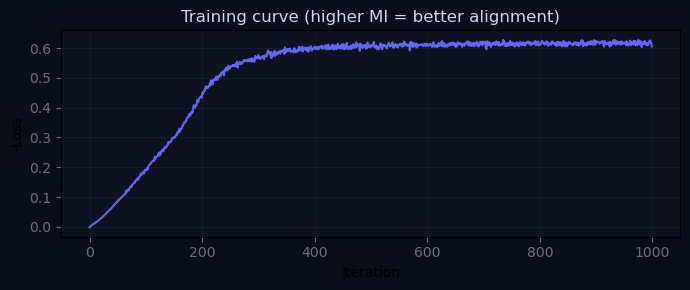


Training done in 95.74s


In [43]:
# ============================================================
# CELL 9 — Training loop  (unchanged logic, 3D data)
# ============================================================
n_iters     = 1000
plot_every  = 20
max_samples = 32768   # voxels per MINE forward pass
lambda_reg  = 1e-4

mi_curve = []
t0 = time.time()

for itr in range(n_iters):
    optimizer.zero_grad(set_to_none=True)

    with torch.cuda.amp.autocast(enabled=(device.type == 'cuda')):
        loss = multi_resolution_loss_3d(
            affine_net, mine_net,
            I_lst, J_lst,
            xyz_lst, ind_lst,
            L=L,
            max_samples=max_samples,
            lambda_reg=lambda_reg
        )

    scaler.scale(loss).backward()
    scaler.step(optimizer)
    scaler.update()

    mi_curve.append((-loss).item())

    if (itr + 1) % plot_every == 0 or itr == 0:
        clear_output(wait=True)
        elapsed = time.time() - t0
        print(f"Iter {itr+1}/{n_iters} | "
              f"-Loss (MI proxy): {mi_curve[-1]:.6f} | "
              f"elapsed: {elapsed:.1f}s")

        plt.figure(figsize=(7, 3))
        plt.plot(mi_curve, color='#6366f1')
        plt.title("Training curve (higher MI = better alignment)",
                  color='#cdd6f4')
        plt.xlabel("Iteration"); plt.ylabel("-Loss")
        plt.grid(alpha=0.3, color='#313244')
        plt.gca().set_facecolor('#0d1120')
        plt.gcf().set_facecolor('#0a0e1a')
        plt.tick_params(colors='#6c7086')
        plt.tight_layout()
        plt.show()

print(f"\nTraining done in {time.time()-t0:.2f}s")

---
## Cell 10 — Warp Full-Resolution Volume & Visualise

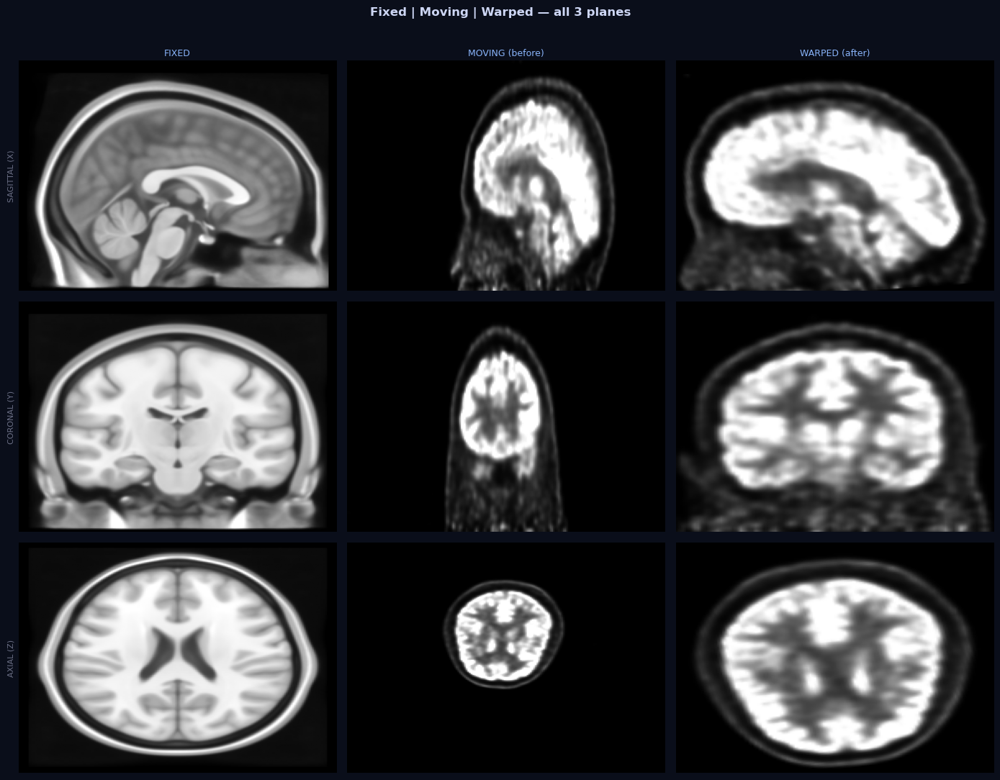

In [44]:
# ============================================================
# CELL 10 — Warp full-resolution volume + 3-plane visualisation
# ============================================================
@torch.no_grad()
def warp_full_resolution_3d(I_np, J_np, affine_net, device):
    """
    3D replacement for warp_full_resolution().
    I_np, J_np : [X, Y, Z]  float32 in [0,1]
    Returns: I_np (fixed), J_warped [X,Y,Z], M_final [4,4]
    """
    # [X,Y,Z] → [Z,Y,X]=[D,H,W]
    I_dhw = np.transpose(I_np, (2,1,0))
    J_dhw = np.transpose(J_np, (2,1,0))

    D, H, W = I_dhw.shape
    J_t = torch.from_numpy(J_dhw).float().to(device)
    J4  = J_t.unsqueeze(0).unsqueeze(0)   # [1,1,D,H,W]

    grid = make_grid_3d(D, H, W, device)  # [D,H,W,3]
    M    = affine_net(0)                   # fine-level params

    Jw_dhw = affine_transform_3d(J4, M, grid).detach().cpu().numpy()  # [D,H,W]

    # back to [X,Y,Z]
    J_warped = np.transpose(Jw_dhw, (2,1,0))
    M_np     = M.detach().cpu().numpy()
    return I_np, J_warped, M_np


I_full = robust_norm01(I_raw)
J_full = robust_norm01(J_raw)

I_out, J_warped, M_final = warp_full_resolution_3d(I_full, J_full, affine_net, device)

print("Final 4×4 affine matrix M:")
print(np.round(M_final, 6))

# ── Interactive 3-plane slicer: Fixed | Before | After ────────────────────────
def slicer_3panel(fixed, moving, warped, title=""):
    nz, ny, nx = fixed.shape[2], fixed.shape[1], fixed.shape[0]

    fig, axes = plt.subplots(3, 3, figsize=(14, 12))
    fig.patch.set_facecolor('#0a0e1a')
    row_labels = ['SAGITTAL (X)', 'CORONAL (Y)', 'AXIAL (Z)']
    col_labels = ['FIXED', 'MOVING (before)', 'WARPED (after)']

    ci = [fixed.shape[0]//2, fixed.shape[1]//2, fixed.shape[2]//2]

    def sl(v, p, i):
        if p==0: return v[i,:,:].T
        if p==1: return v[:,i,:].T
        return v[:,:,i].T

    ims = {}
    for row, plane in enumerate(range(3)):
        for col, (vol, lbl) in enumerate(zip([fixed, moving, warped], col_labels)):
            ax = axes[row, col]
            ax.set_facecolor('#0a0e1a')
            im = ax.imshow(sl(vol, plane, ci[plane]), cmap='gray',
                           origin='lower', aspect='auto', vmin=0, vmax=1)
            ax.axis('off')
            ims[(row, col)] = (ax, im, plane)
            if row == 0:
                ax.set_title(lbl, color='#89b4fa', fontsize=9, pad=5)
            if col == 0:
                ax.set_ylabel(row_labels[row], color='#6c7086', fontsize=8, rotation=90)
                ax.axis('on'); ax.set_xticks([]); ax.set_yticks([])
                for sp in ax.spines.values(): sp.set_visible(False)

    fig.suptitle(title, color='#cdd6f4', fontsize=12, fontweight='bold')
    plt.tight_layout(rect=[0, 0.08, 1, 0.97])

    # Sliders
    style = {'description_width': '90px'}
    layout = widgets.Layout(width='80%', margin='2px auto')
    sl_x = widgets.IntSlider(value=ci[0], min=0, max=nx-1, description='Sagittal X', style=style, layout=layout)
    sl_y = widgets.IntSlider(value=ci[1], min=0, max=ny-1, description='Coronal Y',  style=style, layout=layout)
    sl_z = widgets.IntSlider(value=ci[2], min=0, max=nz-1, description='Axial Z',    style=style, layout=layout)

    def update(x, y, z):
        idx_map = {0: x, 1: y, 2: z}
        for (row, col), (ax, im, plane) in ims.items():
            vol = [fixed, moving, warped][col]
            im.set_data(sl(vol, plane, idx_map[plane]))
        fig.canvas.draw_idle()

    out = widgets.interactive_output(update, {'x': sl_x, 'y': sl_y, 'z': sl_z})
    display(fig, widgets.VBox([sl_x, sl_y, sl_z, out]))


slicer_3panel(I_out, J_full, J_warped,
              title="Fixed | Moving | Warped — all 3 planes")

---
## Cell 11 — Overlay & Difference Visualisation

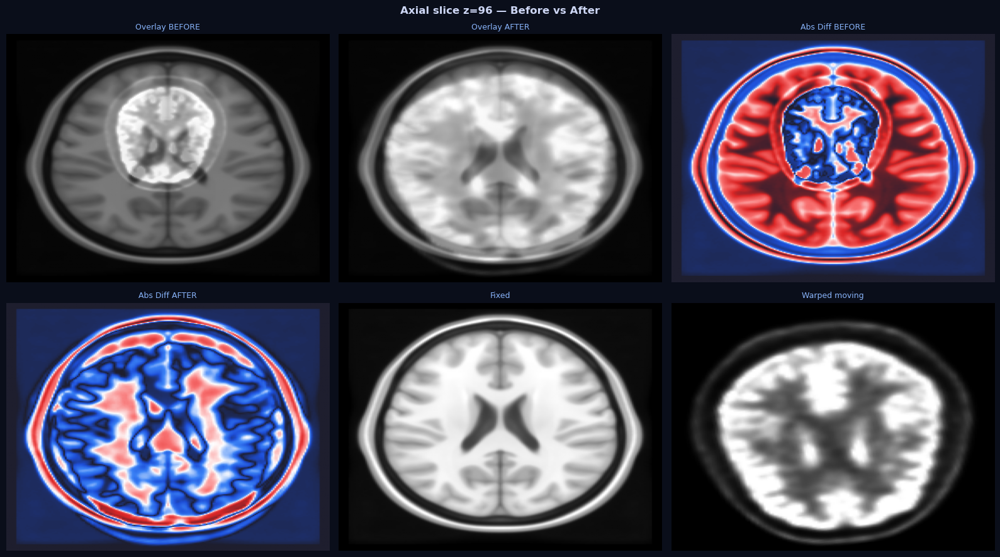


══════════════════════════════════════════════════
  Metric           Before        After      Delta
──────────────────────────────────────────────────
  MSE             0.16341      0.07332   -0.09009
  MAE             0.26081      0.16804   -0.09278
  NCC            -0.01006      0.22836   +0.23842
══════════════════════════════════════════════════


In [45]:
# ============================================================
# CELL 11 — Overlay + Difference maps  (3D, slice by slice)
# ============================================================
from matplotlib.colors import LinearSegmentedColormap
DIFF_CM = LinearSegmentedColormap.from_list('diff',
    ['#1e1e2e','#1d4ed8','#3b82f6','#ffffff','#f87171','#dc2626','#1e1e2e'])

def overlay_3d(A, B, alpha=0.5):
    """Alpha-blend two 3D volumes, return [X,Y,Z] in [0,1]."""
    return np.clip(alpha*A.astype(np.float32) + (1-alpha)*B.astype(np.float32), 0, 1)


ov_before = overlay_3d(I_out, J_full,    alpha=0.5)
ov_after  = overlay_3d(I_out, J_warped,  alpha=0.5)
diff_before = np.abs(I_out - J_full)
diff_after  = np.abs(I_out - J_warped)

# ── 6-panel comparison at centre slices ──────────────────────
z_mid = I_out.shape[2] // 2
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.patch.set_facecolor('#0a0e1a')

panels = [
    (ov_before[:,:,z_mid].T,   plt.cm.gray,  'Overlay BEFORE',    0, 1),
    (ov_after [:,:,z_mid].T,   plt.cm.gray,  'Overlay AFTER',     0, 1),
    (diff_before[:,:,z_mid].T, DIFF_CM,      'Abs Diff BEFORE',   0, diff_before.max()),
    (diff_after [:,:,z_mid].T, DIFF_CM,      'Abs Diff AFTER',    0, diff_before.max()),
    (I_out[:,:,z_mid].T,       plt.cm.gray,  'Fixed',             0, 1),
    (J_warped[:,:,z_mid].T,    plt.cm.gray,  'Warped moving',     0, 1),
]

for ax, (data, cmap, lbl, vmin, vmax) in zip(axes.flat, panels):
    ax.set_facecolor('#0a0e1a')
    ax.imshow(data, cmap=cmap, aspect='auto', origin='lower', vmin=vmin, vmax=vmax)
    ax.set_title(lbl, color='#89b4fa', fontsize=9)
    ax.axis('off')

fig.suptitle(f"Axial slice z={z_mid} — Before vs After",
             color='#cdd6f4', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# ── Metrics ──────────────────────────────────────────────────
mse_b = float(np.mean(diff_before**2))
mse_a = float(np.mean(diff_after**2))
mae_b = float(diff_before.mean())
mae_a = float(diff_after.mean())
ncc_b = float(np.corrcoef(I_out.ravel()[:500000], J_full.ravel()[:500000])[0,1])
ncc_a = float(np.corrcoef(I_out.ravel()[:500000], J_warped.ravel()[:500000])[0,1])

print(f"\n{'═'*50}")
print(f"  {'Metric':<10} {'Before':>12} {'After':>12} {'Delta':>10}")
print(f"{'─'*50}")
print(f"  {'MSE':<10} {mse_b:>12.5f} {mse_a:>12.5f} {mse_a-mse_b:>+10.5f}")
print(f"  {'MAE':<10} {mae_b:>12.5f} {mae_a:>12.5f} {mae_a-mae_b:>+10.5f}")
print(f"  {'NCC':<10} {ncc_b:>12.5f} {ncc_a:>12.5f} {ncc_a-ncc_b:>+10.5f}")
print(f"{'═'*50}")

---
## Cell 12 — Save Results

In [46]:
# ============================================================
# CELL 12 — Save results  (NIfTI, replaces cv2.imwrite PNG)
# ============================================================

def save_nifti(vol_np: np.ndarray, ref_nib, out_path: str):
    """
    Save a numpy [X,Y,Z] volume as NIfTI,
    inheriting affine & header from the fixed image.
    """
    img = nib.Nifti1Image(vol_np.astype(np.float32),
                          ref_nib.affine,
                          ref_nib.header)
    img.header.set_data_dtype(np.float32)
    nib.save(img, out_path)
    sz = os.path.getsize(out_path) / 1024**2
    print(f"  Saved: {out_path}  ({sz:.2f} MB)")


# ── Save volumes ──────────────────────────────────────────────
print("Saving NIfTI outputs …")
save_nifti(I_out,     I_nib, os.path.join(OUT_DIR, 'I_fixed_norm.nii.gz'))
save_nifti(J_full,    I_nib, os.path.join(OUT_DIR, 'J_moving_norm.nii.gz'))
save_nifti(J_warped,  I_nib, os.path.join(OUT_DIR, 'J_warped.nii.gz'))
save_nifti(diff_before, I_nib, os.path.join(OUT_DIR, 'diff_before.nii.gz'))
save_nifti(diff_after,  I_nib, os.path.join(OUT_DIR, 'diff_after.nii.gz'))

# ── Save affine matrix ────────────────────────────────────────
M_path = os.path.join(OUT_DIR, 'M_affine_4x4.npy')
np.save(M_path, M_final)
print(f"  Saved: {M_path}")

# ── Save model weights ────────────────────────────────────────
ckpt_path = os.path.join(OUT_DIR, 'model_weights.pt')
torch.save({
    'affine_net': affine_net.state_dict(),
    'mine_net':   mine_net.state_dict(),
    'M_final':    M_final,
    'mi_curve':   mi_curve,
}, ckpt_path)
print(f"  Saved: {ckpt_path}")

# ── Summary ───────────────────────────────────────────────────
print(f"""
╔══════════════════════════════════════════════════════╗
║   Reg_Aymen 3D — Complete                           ║
╠══════════════════════════════════════════════════════╣
║  Fixed  : {I_path:<42}║
║  Moving : {J_path:<42}║
║  Output : {OUT_DIR:<42}║
╠══════════════════════════════════════════════════════╣
║  MSE  before→after: {mse_b:.5f} → {mse_a:.5f}{'':10}║
║  NCC  before→after: {ncc_b:.5f} → {ncc_a:.5f}{'':10}║
╚══════════════════════════════════════════════════════╝
""")

Saving NIfTI outputs …
  Saved: D:/registration 3d/test_v2_12_10_rania2\I_fixed_norm.nii.gz  (12.52 MB)
  Saved: D:/registration 3d/test_v2_12_10_rania2\J_moving_norm.nii.gz  (26.11 MB)
  Saved: D:/registration 3d/test_v2_12_10_rania2\J_warped.nii.gz  (27.93 MB)
  Saved: D:/registration 3d/test_v2_12_10_rania2\diff_before.nii.gz  (25.87 MB)
  Saved: D:/registration 3d/test_v2_12_10_rania2\diff_after.nii.gz  (27.71 MB)
  Saved: D:/registration 3d/test_v2_12_10_rania2\M_affine_4x4.npy
  Saved: D:/registration 3d/test_v2_12_10_rania2\model_weights.pt

╔══════════════════════════════════════════════════════╗
║   Reg_Aymen 3D — Complete                           ║
╠══════════════════════════════════════════════════════╣
║  Fixed  : D:/registration 3d/MNI152.nii             ║
║  Moving : D:/registration 3d/971882.nii             ║
║  Output : D:/registration 3d/test_v2_12_10_rania2   ║
╠══════════════════════════════════════════════════════╣
║  MSE  before→after: 0.16341 → 0.07332          ║

In [33]:
import nibabel as nib
import numpy as np
import plotly.graph_objects as go

nii = nib.load(os.path.join(OUT_DIR, 'J_warped.nii.gz'))
vol = nii.get_fdata()

# Normalize for display
vol = (vol - vol.min()) / (vol.max() - vol.min())

fig = go.Figure(data=go.Volume(
    x=np.linspace(0, 1, vol.shape[0]),
    y=np.linspace(0, 1, vol.shape[1]),
    z=np.linspace(0, 1, vol.shape[2]),
    value=vol.flatten(),
    opacity=0.1,      # transparency
    surface_count=15  # detail
))

fig.show()

In [34]:
!pip install itkwidgets SimpleITK

In [35]:
import SimpleITK as sitk
import itkwidgets as itkw
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, FloatSlider
import ipywidgets as widgets
from IPython.display import display

# Charger les images
image_base    = sitk.ReadImage("D:/registration 3d/IRM_J_warped.nii.gz")
image_overlay = sitk.ReadImage("D:/registration 3d/IRM_J_warped.nii.gz")

# Affichage 3D avec overlay
viewer = itkw.view(
    image=image_base,
         # pour les segmentations / masques
    gradient_opacity=0.5,           # opacité initiale
    ui_collapsed=False
)

display(viewer)

Viewer(geometries=[], gradient_opacity=0.5, point_sets=[], rendered_image=<itk.itkImagePython.itkImageF3; prox…